# Retail Inventory DQN: a Reproducible Custom-Simulator Study
### Baseline DQN vs. 10× stockout-penalty DQN, with a tuned (s,S) benchmark

A substantive revision of the supplied `RL_Inventory_Management_FINAL (1).ipynb`. Original reference authorship is retained by attribution; this is a revised experiment, not its old saved results.

**Assignment caveat:** this is a custom **single-store Gymnasium** model, not `or-gym/InvManagement-v1`. The latter is a different multi-echelon/Box-action problem. No equivalence or instructor approval is claimed. Obtain an exception or migrate before claiming strict compliance with that environment requirement.

**Run all from a fresh free Colab CPU runtime.** No Drive mount, paid GPU, external dataset or private credential is required. The notebook is self-contained and writes its source, tests, models, raw metrics and figures. Training is real; gains are never guaranteed. Final report writing is separate.

## Experimental plan
1. Install pinned dependencies, define explicit inventory/accounting rules and run invariant tests.
2. Measure CPU speed with a discarded 10,000-step benchmark.
3. Tune the heuristic using validation demand only. Train both DQN variants for **150,000 steps per seed**, with three seeds and identical budgets.
4. Select checkpoints on validation original-cost profit; evaluate on **100 independent 30-day months per condition**, matched across all policies.
5. Analyze a three-day, triple-mean-demand shock, save evidence and download results.


## 0. Dependencies and run settings
Versions below are pinned for reproducibility; actual successfully imported versions and execution hardware are recorded in the manifest. A fresh runtime avoids incompatible already-imported libraries. CPU is suitable for this small network. Installation may take a few minutes; do not purchase compute.


In [1]:
import os, sys, subprocess, time, json, platform
from pathlib import Path
os.environ['MPLCONFIGDIR'] = '/tmp/retail_inventory_mpl'
subprocess.check_call([sys.executable,'-m','pip','install','-q','torch==2.7.1','--index-url','https://download.pytorch.org/whl/cpu'])
subprocess.check_call([sys.executable,'-m','pip','install','-q','stable-baselines3==2.7.0','gymnasium==1.2.0','numpy==2.3.5','pandas==2.2.3','matplotlib==3.10.8','pytest==8.4.2'])
TRAIN_STEPS = 150_000
TRAIN_SEEDS = (11, 22, 33)
assert 100_000 <= TRAIN_STEPS <= 300_000
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
print('Pinned dependencies installed. CPU experiment configuration:', TRAIN_STEPS, TRAIN_SEEDS)


Pinned dependencies installed. CPU experiment configuration: 150000 (11, 22, 33)


## 1. Custom environment and reproducible experiment implementation

**State:** normalized on-hand stock, every pipeline bucket, and fraction of month remaining. Historical IID Poisson demand is not predictive and is deliberately omitted. **Action:** order requests 0, 5, …, 120 units; capacity-constrained acceptance is logged. This coarser grid reduces the original 121-action DQN difficulty and applies identically to both variants.

**Timing:** choose order → receive previously due stock → observe demand and sell → charge end-of-day holding. Day-t orders arrive before day-(t+2) demand. Capacity 250 reserves on-hand plus *all* pipeline stock, so arrivals are never silently discarded. This reservation is conservative and differs from a warehouse-only capacity constraint.

**Ledger:** all policies pay for initial 40 units and newly accepted orders; unsold terminal stock plus the whole pipeline is credited at unit cost. With price 100, unit cost 60, holding 2 and original stockout penalty 50, episode profit reconciles to 40 × sold units − holding costs − 50 × lost units. Full-cost salvage is a simplifying assumption, not guaranteed retail resale value.

**Training reward:** original business profit/1,000 for baseline; `(business_profit − 9 × original_stockout_cost)/1,000` for the 10× penalty variant. Keep shaped reward separate from original-cost evaluation. Both use [64,64] MLPs, gamma=1.0 for this finite time-observed horizon, the same hyperparameters and the same three seeds. This aligns the training objective with undiscounted monthly totals.

The source cell writes an importable module so the tests, notebook and saved code use exactly the same implementation. Functions are grouped as environment → demand/policies → training/evaluation → plots.


In [2]:
%%writefile inventory_experiment.py
"""Revision of the supplied RL_Inventory_Management_FINAL notebook.
Custom single-store simulator; NOT or-gym InvManagement-v1.
"""
from __future__ import annotations
import json, platform, time
from pathlib import Path
import numpy as np
import pandas as pd
import gymnasium as gym
from gymnasium import spaces

class InventoryEnv(gym.Env):
    """30-day lost-sales problem with capacity reserved for ALL pipeline stock.

    Decision -> arrivals due today -> demand -> holding charge. An order on day
    t arrives before demand on day t+2. Integer quantities, five-unit action grid.
    Opening inventory is purchased; all ending on-hand/pipeline stock is credited
    at unit cost. This explicit salvage assumption prevents unpaid opening stock
    or hidden terminal purchasing bias; it is not a real retail cash-flow model.
    """
    metadata = {"render_modes": []}
    def __init__(self, penalty_multiplier=1., horizon=30, lead_time=2,
                 capacity=250, max_order=120, demand_mean=20., initial_inventory=40,
                 price=100., unit_cost=60., holding_cost=2., stockout_penalty=50.):
        super().__init__()
        for name,value in [('horizon',horizon),('lead_time',lead_time),('capacity',capacity),('max_order',max_order)]:
            if not isinstance(value,(int,np.integer)) or value<=0: raise ValueError(f'{name} must be a positive integer')
        if not isinstance(initial_inventory,(int,np.integer)) or not 0<=initial_inventory<=capacity:
            raise ValueError('initial_inventory must be an integer within capacity')
        if max_order%5: raise ValueError('max_order must be divisible by action grid size 5')
        if any(not np.isfinite(x) or x<0 for x in [penalty_multiplier,demand_mean,price,unit_cost,holding_cost,stockout_penalty]):
            raise ValueError('Economic and demand parameters must be finite and non-negative')
        self.penalty_multiplier=float(penalty_multiplier)
        self.horizon=horizon; self.lead_time=lead_time; self.capacity=capacity
        self.max_order=max_order; self.demand_mean=demand_mean
        self.initial_inventory=initial_inventory; self.price=price
        self.unit_cost=unit_cost; self.holding_cost=holding_cost
        self.stockout_penalty=stockout_penalty
        self.quantities=np.arange(0,max_order+1,5,dtype=int)
        self.action_space=spaces.Discrete(len(self.quantities))
        # on-hand, each lead-time bucket, time remaining. IID demand history
        # is intentionally omitted: it does not forecast tomorrow's distribution.
        self.observation_space=spaces.Box(0.,1.,shape=(lead_time+2,),dtype=np.float32)
    def _obs(self):
        return np.array([self.on_hand/self.capacity,*[q/self.capacity for q in self.pipeline],
                         (self.horizon-self.day)/self.horizon],dtype=np.float32)
    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.on_hand=self.initial_inventory; self.pipeline=[0]*self.lead_time; self.day=0
        self.demands=None
        if options and 'demands' in options:
            raw=np.asarray(options['demands'])
            if raw.shape!=(self.horizon,) or not np.issubdtype(raw.dtype,np.number) or not np.all(np.isfinite(raw)) or np.any(raw<0) or np.any(raw!=np.floor(raw)):
                raise ValueError('Demand scenario must have horizon non-negative integer values')
            self.demands=raw.astype(int)
        return self._obs(),{}
    def step(self, action):
        if self.day>=self.horizon: raise RuntimeError('Call reset after episode end')
        if not self.action_space.contains(action): raise ValueError('Invalid discrete action')
        requested=int(self.quantities[action])
        # Capacity reservation: no accepted inventory ever disappears at arrival.
        accepted=min(requested,self.capacity-self.on_hand-sum(self.pipeline))
        arriving=self.pipeline.pop(0)
        self.on_hand+=arriving; self.pipeline.append(accepted)
        demand=int(self.np_random.poisson(self.demand_mean)) if self.demands is None else int(self.demands[self.day])
        sold=min(self.on_hand,demand); lost=demand-sold; self.on_hand-=sold
        revenue=self.price*sold; purchase=self.unit_cost*accepted
        opening=self.unit_cost*self.initial_inventory if self.day==0 else 0.
        holding=self.holding_cost*self.on_hand; stockout=self.stockout_penalty*lost
        self.day+=1; terminated=self.day==self.horizon
        salvage=self.unit_cost*(self.on_hand+sum(self.pipeline)) if terminated else 0.
        business_profit=revenue-purchase-opening-holding-stockout+salvage
        shaped_profit=business_profit-(self.penalty_multiplier-1)*stockout
        info=dict(day=self.day,demand=demand,sold=sold,lost_units=lost,on_hand=self.on_hand,
                  in_transit=sum(self.pipeline),arrivals=arriving,requested_order=requested,
                  accepted_order=accepted,rejected_order=requested-accepted,revenue=revenue,
                  purchase_cost=purchase,opening_inventory_cost=opening,holding_cost=holding,
                  stockout_cost=stockout,terminal_salvage=salvage,business_profit=business_profit,
                  shaped_profit=shaped_profit,stockout_day=int(lost>0))
        return self._obs(),shaped_profit/1000.,terminated,False,info

def scenarios(seed,n=100,stress=False,horizon=30):
    # Each episode has its own independent RNG stream; seed banks never overlap.
    children=np.random.SeedSequence(seed).spawn(n)
    rates=np.full(horizon,20.)
    if stress: rates[14:17]*=3 # days 15-17, no warning in the observation
    return np.stack([np.random.default_rng(s).poisson(rates) for s in children])

def heuristic(s,S):
    def policy(obs,env):
        position=env.on_hand+sum(env.pipeline)
        target=min(env.max_order,max(0,S-position)) if position<s else 0
        return int(np.argmin(abs(env.quantities-target)))
    return policy

def evaluate(policy,bank,policy_name,training_seed=-1,scenario='normal'):
    env=InventoryEnv(); rows=[]; trajectories=[]
    for episode,demands in enumerate(bank):
        obs,_=env.reset(options={'demands':demands}); daily=[]
        while True:
            action=policy(obs,env); obs,_,done,_,info=env.step(action); daily.append(info)
            if done: break
        df=pd.DataFrame(daily)
        row={k:float(df[k].sum()) for k in ['business_profit','holding_cost','stockout_cost','lost_units','demand','sold','stockout_day','revenue','purchase_cost','opening_inventory_cost','terminal_salvage']}
        row.update(policy=policy_name,training_seed=training_seed,scenario=scenario,episode=episode,
                   average_daily_profit=row['business_profit']/env.horizon,
                   average_daily_holding=row['holding_cost']/env.horizon,
                   fill_rate=row['sold']/row['demand'] if row['demand'] else 1.,
                   stockout_day_rate=row['stockout_day']/env.horizon,
                   ending_on_hand=env.on_hand,ending_pipeline=sum(env.pipeline))
        rows.append(row)
        if episode==0:
            df['policy']=policy_name; df['training_seed']=training_seed; df['scenario']=scenario
            trajectories.append(df)
    return pd.DataFrame(rows),pd.concat(trajectories,ignore_index=True)

def model_policy(model):
    return lambda obs,env: int(model.predict(obs,deterministic=True)[0])

def make_model(seed,penalty_multiplier,log_dir):
    import torch
    from stable_baselines3 import DQN
    from stable_baselines3.common.monitor import Monitor
    torch.set_num_threads(1)
    env=Monitor(InventoryEnv(penalty_multiplier=penalty_multiplier),str(log_dir),
                info_keywords=('business_profit',))
    return DQN('MlpPolicy',env,learning_rate=3e-4,buffer_size=50000,
               learning_starts=3000,batch_size=128,gamma=1.0,train_freq=4,
               gradient_steps=1,target_update_interval=1000,exploration_fraction=.5,
               exploration_final_eps=.05,policy_kwargs={'net_arch':[64,64]},seed=seed,
               device='cpu',verbose=0)

def train_and_evaluate(output='artifacts',steps=150_000,seeds=(11,22,33)):
    """Train from scratch; tune only on validation; then unlock fixed final test banks."""
    import torch, stable_baselines3, gymnasium, matplotlib
    from stable_baselines3.common.callbacks import BaseCallback
    out=Path(output); out.mkdir(exist_ok=True,parents=True)
    for p in ['models','logs','metrics','figures']: (out/p).mkdir(exist_ok=True)
    val=scenarios(10100,50)
    grid=[]
    for s in range(30,101,10):
        for S in range(max(50,s),141,10):
            d,_=evaluate(heuristic(s,S),val,'heuristic')
            grid.append(dict(s=s,S=S,validation_profit=d.business_profit.mean()))
    grid=pd.DataFrame(grid).sort_values('validation_profit',ascending=False)
    grid.to_csv(out/'metrics/heuristic_validation.csv',index=False)
    chosen=grid.iloc[0]; best_s,best_S=int(chosen.s),int(chosen.S)
    print(f'Validation-selected heuristic: s={best_s}, S={best_S}',flush=True)
    training_rows=[]; validation_rows=[]; timing=[]; models={}
    class Diagnostics(BaseCallback):
        def __init__(self,label,seed):
            super().__init__(); self.label=label; self.seed=seed; self.ep=[]; self.best=-np.inf
        def _on_step(self):
            info=self.locals['infos'][0]; self.ep.append(info)
            if self.locals['dones'][0]:
                training_rows.append(dict(policy=self.label,training_seed=self.seed,step=self.num_timesteps,
                    business_profit=sum(x['business_profit'] for x in self.ep),
                    shaped_profit=sum(x['shaped_profit'] for x in self.ep),
                    lost_units=sum(x['lost_units'] for x in self.ep),
                    mean_order=np.mean([x['accepted_order'] for x in self.ep]),
                    epsilon=self.model.exploration_rate))
                self.ep=[]
            if self.num_timesteps % 25000==0 or self.num_timesteps==steps:
                d,_=evaluate(model_policy(self.model),val,self.label,self.seed)
                score=float(d.business_profit.mean())
                validation_rows.append(dict(policy=self.label,training_seed=self.seed,step=self.num_timesteps,
                    business_profit=score,fill_rate=float(d.fill_rate.mean()),lost_units=float(d.lost_units.mean())))
                if score>self.best:
                    self.best=score; self.model.save(out/f'models/{self.label}_seed{self.seed}_best.zip')
                print(f'{self.label} seed {self.seed}: {self.num_timesteps:,} steps, validation profit {score:,.1f}',flush=True)
            return True
    from stable_baselines3 import DQN
    for seed in seeds:
        for label,mult in [('baseline_dqn',1.),('penalty10_dqn',10.)]:
            start=time.perf_counter(); model=make_model(seed,mult,out/f'logs/{label}_{seed}')
            callback=Diagnostics(label,seed); model.learn(total_timesteps=steps,callback=callback)
            model.save(out/f'models/{label}_seed{seed}_final.zip')
            models[(label,seed)]=DQN.load(out/f'models/{label}_seed{seed}_best.zip',device='cpu')
            timing.append(dict(policy=label,training_seed=seed,steps=steps,seconds=time.perf_counter()-start))
            pd.DataFrame(training_rows).to_csv(out/'metrics/training_episodes.csv',index=False)
            pd.DataFrame(validation_rows).to_csv(out/'metrics/validation_checkpoints.csv',index=False)
    # Test data never participates in hyperparameter/checkpoint/heuristic selection.
    all_metrics=[]; all_trajectories=[]
    for scenario,bank in [('normal',scenarios(20200,100)),('stress',scenarios(30300,100,True))]:
        pd.DataFrame(bank).to_csv(out/f'metrics/{scenario}_demand_bank.csv',index=False)
        for label,policy,seed in [('sS_heuristic',heuristic(best_s,best_S),-1),
                                  *[(k[0],model_policy(v),k[1]) for k,v in models.items()]]:
            d,t=evaluate(policy,bank,label,seed,scenario)
            all_metrics.append(d); all_trajectories.append(t)
    metrics=pd.concat(all_metrics,ignore_index=True); traj=pd.concat(all_trajectories,ignore_index=True)
    metrics.to_csv(out/'metrics/test_episodes.csv',index=False)
    traj.to_csv(out/'metrics/representative_trajectories.csv',index=False)
    pd.DataFrame(val).to_csv(out/'metrics/validation_demand_bank.csv',index=False)
    summary=metrics.groupby(['scenario','policy']).agg(
        monthly_profit=('business_profit','mean'),daily_profit=('average_daily_profit','mean'),
        monthly_holding=('holding_cost','mean'),lost_units=('lost_units','mean'),fill_rate=('fill_rate','mean'),
        stockout_days=('stockout_day','mean'),stockout_day_rate=('stockout_day_rate','mean')).reset_index()
    summary.to_csv(out/'metrics/summary.csv',index=False)
    per_seed=metrics.groupby(['scenario','policy','training_seed']).agg(
        profit=('business_profit','mean'),fill_rate=('fill_rate','mean'),lost_units=('lost_units','mean')).reset_index()
    per_seed.to_csv(out/'metrics/per_seed_summary.csv',index=False)
    # Pair by demand episode, average RL seeds within episode first. The interval
    # measures demand uncertainty CONDITIONAL on these trained models, not seed uncertainty.
    paired=[]; rng=np.random.default_rng(40400)
    for scenario in ['normal','stress']:
        sub=metrics[metrics.scenario==scenario]
        h=sub[sub.policy=='sS_heuristic'].set_index('episode').business_profit.sort_index()
        for label in ['baseline_dqn','penalty10_dqn']:
            r=sub[sub.policy==label].groupby('episode').business_profit.mean().sort_index()
            diff=(r-h).to_numpy(); boot=rng.choice(diff,(5000,len(diff)),replace=True).mean(axis=1)
            paired.append(dict(scenario=scenario,comparison=f'{label} minus heuristic',profit_difference=diff.mean(),
                               ci95_low=np.quantile(boot,.025),ci95_high=np.quantile(boot,.975)))
        b=sub[sub.policy=='baseline_dqn'].groupby('episode').business_profit.mean().sort_index()
        p=sub[sub.policy=='penalty10_dqn'].groupby('episode').business_profit.mean().sort_index()
        diff=(p-b).to_numpy(); boot=rng.choice(diff,(5000,len(diff)),replace=True).mean(axis=1)
        paired.append(dict(scenario=scenario,comparison='penalty10_dqn minus baseline_dqn',profit_difference=diff.mean(),
                           ci95_low=np.quantile(boot,.025),ci95_high=np.quantile(boot,.975)))
    pd.DataFrame(paired).to_csv(out/'metrics/paired_comparisons.csv',index=False)
    manifest=dict(python=platform.python_version(),platform=platform.platform(),processor=platform.processor(),
        torch=torch.__version__,gymnasium=gymnasium.__version__,stable_baselines3=stable_baselines3.__version__,
        numpy=np.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__,cuda=torch.cuda.is_available(),
        torch_threads=torch.get_num_threads(),training_steps_per_model=steps,training_seeds=list(seeds),
        heuristic={'s':best_s,'S':best_S},timings=timing,total_training_seconds=sum(x['seconds'] for x in timing),
        validation_bank_seed=10100,normal_test_bank_seed=20200,stress_test_bank_seed=30300,
        note='Custom single-store environment; not or-gym. No test-driven tuning. Test episodes shared across models.')
    (out/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
    return metrics,traj,summary,pd.DataFrame(training_rows),pd.DataFrame(validation_rows)

def plot_results(metrics,traj,summary,training,validation,output='artifacts'):
    import matplotlib.pyplot as plt
    out=Path(output)/'figures'; out.mkdir(exist_ok=True,parents=True)
    plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
    colors={'baseline_dqn':'#2866a4','penalty10_dqn':'#cd6524','sS_heuristic':'#31835c'}
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    for (label,seed),df in training.groupby(['policy','training_seed']):
        for ax,col,title in zip(axes,['business_profit','shaped_profit'],['Original business profit (training, exploratory)','Shaped objective (different reward definitions)']):
            ax.plot(df.step,df[col].rolling(100,min_periods=100).mean(),color=colors[label],alpha=.65,label=f'{label}, seed {seed}')
            ax.set(title=title,xlabel='Training timesteps',ylabel='30-day total, 100-episode moving average')
    axes[0].legend(fontsize=7); fig.tight_layout();fig.savefig(out/'training_curves.png');plt.show()
    fig,ax=plt.subplots(figsize=(9,4))
    for (label,seed),df in validation.groupby(['policy','training_seed']):
        ax.plot(df.step,df.business_profit,marker='o',label=f'{label}, seed {seed}')
    ax.set(title='Checkpoint validation under original business costs',xlabel='Training timesteps',ylabel='Mean 30-day profit');ax.legend(fontsize=7,ncol=2)
    fig.tight_layout();fig.savefig(out/'validation_curves.png');plt.show()
    fig,axes=plt.subplots(2,3,figsize=(13,7))
    for row,scenario in enumerate(['normal','stress']):
        data=summary[summary.scenario==scenario].set_index('policy').reindex(['sS_heuristic','baseline_dqn','penalty10_dqn'])
        for ax,col,title in zip(axes[row],['monthly_profit','monthly_holding','lost_units'],['30-day profit','30-day holding cost','30-day lost units']):
            ax.bar(['(s,S)','DQN','10x DQN'],data[col],color=[colors[x] for x in data.index]);ax.set_title(f'{scenario}: {title}')
    fig.tight_layout();fig.savefig(out/'normal_stress_comparison.png');plt.show()
    # Fixed first test episode and fixed seed 11, not an attractive cherry-picked run.
    fig,axes=plt.subplots(3,1,figsize=(12,9),sharex=True)
    rep=traj[(traj.scenario=='stress') & traj.training_seed.isin([-1,11])]
    for label,df in rep.groupby('policy'):
        for ax,col in zip(axes,['on_hand','in_transit','accepted_order']):
            ax.plot(df.day,df[col],label=label,color=colors[label]);ax.set_ylabel(col.replace('_',' '))
    demand=rep[rep.policy=='sS_heuristic']
    axes[0].plot(demand.day,demand.demand,'k--',label='Demand')
    for ax in axes: ax.axvspan(14.5,17.5,color='red',alpha=.08);ax.legend(fontsize=8)
    axes[0].set_title('Fixed representative stress month: days 15–17 have triple expected demand')
    axes[-1].set_xlabel('Day');fig.tight_layout();fig.savefig(out/'stress_trajectory.png');plt.show()


Writing inventory_experiment.py


In [3]:
from inventory_experiment import InventoryEnv, scenarios, heuristic, evaluate, model_policy, make_model, train_and_evaluate, plot_results
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
print('Python:', platform.python_version(), '| CPU count:', os.cpu_count())
print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
env = InventoryEnv()
print('Observation:', env.observation_space, '| Action:', env.action_space)
print('Initial normalized state:', env.reset(seed=42)[0])


Python: 3.13.16 | CPU count: 2
PyTorch: 2.7.1+cpu | CUDA available: False
Observation: Box(0.0, 1.0, (4,), float32) | Action: Discrete(25)
Initial normalized state: [0.16 0.   0.   1.  ]


## 2. Environment invariants before training
The tests cover demand reproducibility, exact lead-time/FIFO behavior, mass balance, capacity, invalid inputs, normalized states, opening/terminal/pipeline accounting, unchanged original economics under shaping, matched test demand, and the stress window. Any failure stops the notebook before training. These are automated checks, not assertions that the custom model matches or-gym.


In [4]:
%%writefile test_inventory.py
"""Regression tests for the revised inventory model's physical and monetary ledger.

Run from this folder: .venv/bin/python -m pytest -q test_inventory.py
The tests intentionally require invalid model inputs to fail explicitly.
"""
from __future__ import annotations

import numpy as np
import pytest
from gymnasium.utils.env_checker import check_env

from inventory_experiment import InventoryEnv, evaluate, heuristic, scenarios


def run_episode(env, actions, *, demands=None, seed=101):
    options = None if demands is None else {"demands": demands}
    first, _ = env.reset(seed=seed, options=options)
    trajectory = []
    for action in actions:
        obs, reward, terminated, truncated, info = env.step(action)
        trajectory.append((obs.copy(), reward, terminated, truncated, info.copy()))
    return first, trajectory


def test_gymnasium_environment_checker():
    check_env(InventoryEnv(), skip_render_check=True)


def test_seeded_reset_reproduces_observations_rewards_and_demands():
    env = InventoryEnv(horizon=30)
    actions = [0, 2, 4, 0, 12] * 6
    first, expected = run_episode(env, actions, seed=2718)
    run_episode(env, actions, seed=17)
    restarted, actual = run_episode(env, actions, seed=2718)
    np.testing.assert_array_equal(first, restarted)
    for lhs, rhs in zip(expected, actual):
        np.testing.assert_array_equal(lhs[0], rhs[0])
        assert lhs[1:] == rhs[1:]
    _, different = run_episode(env, actions, seed=2719)
    assert [x[4]["demand"] for x in expected] != [x[4]["demand"] for x in different]


@pytest.mark.parametrize("lead_time", [1, 2, 3, 5])
def test_observation_bounds_dtype_pipeline_and_time(lead_time):
    env = InventoryEnv(lead_time=lead_time, horizon=40, capacity=123)
    obs, info = env.reset(seed=99)
    assert isinstance(info, dict)
    assert obs.dtype == np.float32
    assert obs.shape == (lead_time + 2,)
    assert env.observation_space.contains(obs)
    rng = np.random.default_rng(818)
    for day in range(env.horizon):
        obs, reward, terminated, truncated, info = env.step(int(rng.integers(env.action_space.n)))
        assert env.observation_space.contains(obs)
        assert np.isfinite(reward)
        assert not truncated
        assert terminated == (day == env.horizon - 1)
        assert obs[0] == pytest.approx(env.on_hand / env.capacity)
        np.testing.assert_allclose(obs[1:-1], np.asarray(env.pipeline) / env.capacity)
        assert obs[-1] == pytest.approx((env.horizon - day - 1) / env.horizon)
    assert obs[-1] == 0


@pytest.mark.parametrize("lead_time", [1, 2, 3, 5])
def test_order_arrives_exactly_lead_time_days_after_decision(lead_time):
    horizon = lead_time + 2
    env = InventoryEnv(horizon=horizon, lead_time=lead_time, initial_inventory=0, holding_cost=0)
    _, trajectory = run_episode(env, [3] + [0] * (horizon - 1), demands=[0] * horizon)
    expected_arrivals = [0] * horizon
    expected_arrivals[lead_time] = 15
    assert [t[4]["arrivals"] for t in trajectory] == expected_arrivals
    assert env.on_hand == 15
    assert sum(env.pipeline) == 0
    assert sum(t[4]["business_profit"] for t in trajectory) == 0


def test_arrivals_are_available_before_same_day_demand():
    env = InventoryEnv(horizon=3, lead_time=2, initial_inventory=0)
    _, trajectory = run_episode(env, [2, 0, 0], demands=[0, 0, 12])
    last = trajectory[-1][4]
    assert last["arrivals"] == 10
    assert last["sold"] == 10
    assert last["lost_units"] == 2
    assert last["on_hand"] == 0


def test_capacity_reserves_all_pipeline_and_never_discards_arrivals():
    env = InventoryEnv(horizon=5, lead_time=2, initial_inventory=100, capacity=125, max_order=50)
    _, trajectory = run_episode(env, [10] * 5, demands=[0] * 5)
    infos = [t[4] for t in trajectory]
    assert [i["accepted_order"] for i in infos] == [25, 0, 0, 0, 0]
    assert [i["arrivals"] for i in infos] == [0, 0, 25, 0, 0]
    assert [i["rejected_order"] for i in infos] == [25, 50, 50, 50, 50]
    assert env.on_hand == 125
    assert sum(env.pipeline) == 0


def test_capacity_is_checked_before_arrivals_and_demand():
    env = InventoryEnv(horizon=2, initial_inventory=120, capacity=125)
    _, trajectory = run_episode(env, [4, 4], demands=[100, 0])
    assert trajectory[0][4]["accepted_order"] == 5
    assert trajectory[1][4]["accepted_order"] == 20


@pytest.mark.parametrize("seed", range(12))
def test_mass_balance_fifo_and_capacity_across_random_trajectories(seed):
    horizon, lead_time, initial = 50, 3, 40
    env = InventoryEnv(horizon=horizon, lead_time=lead_time, initial_inventory=initial, capacity=123)
    rng = np.random.default_rng(seed)
    demands = rng.poisson(35, size=horizon)
    obs, _ = env.reset(seed=seed, options={"demands": demands})
    total_accepted = total_sold = 0
    history = []
    for day in range(horizon):
        old_position = env.on_hand + sum(env.pipeline)
        action = int(rng.integers(env.action_space.n))
        obs, _, terminated, _, info = env.step(action)
        history.append(info)
        total_accepted += info["accepted_order"]
        total_sold += info["sold"]
        assert info["accepted_order"] == min(info["requested_order"], env.capacity - old_position)
        assert info["requested_order"] == info["accepted_order"] + info["rejected_order"]
        assert info["arrivals"] == (history[day - lead_time]["accepted_order"] if day >= lead_time else 0)
        assert initial + total_accepted == total_sold + env.on_hand + sum(env.pipeline)
        assert 0 <= env.on_hand + sum(env.pipeline) <= env.capacity
        assert info["demand"] == info["sold"] + info["lost_units"]
        assert info["stockout_day"] == int(info["lost_units"] > 0)
        assert info["in_transit"] == sum(env.pipeline)
        assert env.observation_space.contains(obs)
        assert terminated == (day == horizon - 1)


@pytest.mark.parametrize("action", [-1, 25, 999, 1.25, "2", None, [], np.array([1])])
def test_invalid_actions_rejected_without_mutating_state(action):
    env = InventoryEnv()
    obs, _ = env.reset(seed=42)
    old_state = (env.day, env.on_hand, tuple(env.pipeline))
    with pytest.raises(ValueError, match="[Ii]nvalid.*action"):
        env.step(action)
    assert (env.day, env.on_hand, tuple(env.pipeline)) == old_state
    np.testing.assert_array_equal(env._obs(), obs)


def test_cannot_step_past_terminal_state_and_reset_clears_pipeline():
    env = InventoryEnv(horizon=1)
    env.reset(seed=1)
    _, _, terminated, truncated, _ = env.step(4)
    assert terminated and not truncated
    with pytest.raises(RuntimeError, match="reset"):
        env.step(0)
    obs, _ = env.reset(seed=1)
    assert env.day == 0
    assert env.on_hand == env.initial_inventory
    assert env.pipeline == [0] * env.lead_time
    assert obs[-1] == 1


def test_opening_holding_and_terminal_accounting_hand_calculation():
    env = InventoryEnv(horizon=3, initial_inventory=10, lead_time=2)
    _, trajectory = run_episode(env, [1, 0, 0], demands=[4, 12, 0])
    infos = [t[4] for t in trajectory]
    assert [i["opening_inventory_cost"] for i in infos] == [600, 0, 0]
    assert [i["purchase_cost"] for i in infos] == [300, 0, 0]
    assert [i["holding_cost"] for i in infos] == [12, 0, 10]
    assert [i["stockout_cost"] for i in infos] == [0, 300, 0]
    assert [i["terminal_salvage"] for i in infos] == [0, 0, 300]
    assert [i["business_profit"] for i in infos] == [-512, 300, 290]
    assert sum(i["business_profit"] for i in infos) == 78
    assert sum(t[1] for t in trajectory) == pytest.approx(0.078)


def test_terminal_credit_includes_all_undelivered_pipeline():
    env = InventoryEnv(horizon=2, lead_time=3, initial_inventory=10)
    _, trajectory = run_episode(env, [2, 3], demands=[4, 3])
    infos = [t[4] for t in trajectory]
    assert [i["arrivals"] for i in infos] == [0, 0]
    assert env.on_hand == 3
    assert sum(env.pipeline) == 25
    assert infos[-1]["terminal_salvage"] == 60 * (3 + 25)
    assert sum(i["business_profit"] for i in infos) == 262


@pytest.mark.parametrize("seed", range(8))
def test_episode_profit_reconciles_to_sold_margin_less_operating_costs(seed):
    env = InventoryEnv(horizon=30, lead_time=3, initial_inventory=40)
    rng = np.random.default_rng(seed)
    actions = rng.integers(env.action_space.n, size=env.horizon).tolist()
    _, trajectory = run_episode(env, actions, seed=seed)
    infos = [t[4] for t in trajectory]
    total_profit = sum(i["business_profit"] for i in infos)
    expected = sum((env.price - env.unit_cost) * i["sold"] - i["holding_cost"] - i["stockout_cost"] for i in infos)
    assert total_profit == pytest.approx(expected)
    for info in infos:
        assert info["business_profit"] == pytest.approx(info["revenue"] - info["purchase_cost"] - info["opening_inventory_cost"] - info["holding_cost"] - info["stockout_cost"] + info["terminal_salvage"])


@pytest.mark.parametrize("multiplier", [0.5, 1.0, 2.0, 10.0])
def test_reward_shaping_preserves_original_business_profit_and_transitions(multiplier):
    demands = [5, 80, 10, 100, 0, 55]
    actions = [2, 5, 0, 8, 4, 1]
    base = InventoryEnv(horizon=6, penalty_multiplier=1)
    shaped = InventoryEnv(horizon=6, penalty_multiplier=multiplier)
    _, expected = run_episode(base, actions, demands=demands)
    _, actual = run_episode(shaped, actions, demands=demands)
    for lhs, rhs in zip(expected, actual):
        np.testing.assert_array_equal(lhs[0], rhs[0])
        assert lhs[2:4] == rhs[2:4]
        li, ri = lhs[4], rhs[4]
        for key in li:
            if key != "shaped_profit":
                assert li[key] == ri[key]
        assert ri["shaped_profit"] == pytest.approx(ri["business_profit"] - (multiplier - 1) * ri["stockout_cost"])
        assert rhs[1] * 1000 == pytest.approx(ri["shaped_profit"])
    assert sum(t[4]["business_profit"] for t in expected) == sum(t[4]["business_profit"] for t in actual)


def test_scenario_banks_are_repeatable_and_seeds_change_realizations():
    a = scenarios(303, n=8)
    b = scenarios(303, n=8)
    c = scenarios(304, n=8)
    np.testing.assert_array_equal(a, b)
    assert a.shape == (8, 30)
    assert np.issubdtype(a.dtype, np.integer)
    assert (a >= 0).all()
    assert not np.array_equal(a, c)
    assert len({tuple(row) for row in a}) == len(a)


def test_evaluation_uses_identical_demand_bank_for_every_policy():
    bank = scenarios(5101, n=6)
    original = bank.copy()
    zero_rows, zero_days = evaluate(lambda obs, env: 0, bank, "zero")
    stock_rows, stock_days = evaluate(heuristic(60, 95), bank, "heuristic")
    np.testing.assert_array_equal(bank, original)
    np.testing.assert_array_equal(zero_rows["demand"], bank.sum(axis=1))
    np.testing.assert_array_equal(stock_rows["demand"], bank.sum(axis=1))
    np.testing.assert_array_equal(zero_days["demand"], bank[0])
    np.testing.assert_array_equal(stock_days["demand"], bank[0])
    for rows in (zero_rows, stock_rows):
        np.testing.assert_allclose(rows["average_daily_profit"], rows["business_profit"] / 30)
        np.testing.assert_allclose(rows["fill_rate"], rows["sold"] / rows["demand"])
        np.testing.assert_allclose(rows["stockout_day_rate"], rows["stockout_day"] / 30)
        np.testing.assert_allclose(rows["business_profit"], rows["revenue"] - rows["purchase_cost"] - rows["opening_inventory_cost"] - rows["holding_cost"] - rows["stockout_cost"] + rows["terminal_salvage"])


def test_zero_demand_fill_rate_is_one():
    rows, _ = evaluate(lambda obs, env: 0, np.zeros((2, 30), dtype=int), "zero")
    assert (rows["fill_rate"] == 1).all()
    assert (rows["stockout_day_rate"] == 0).all()


def test_three_day_stress_has_correct_calendar_window_and_intensity():
    # Fixed seed and generous tolerances make this a stable distribution regression.
    # Normal and stress are separate banks; matching is across policies WITHIN
    # each condition, not a claim of identical non-shock demand across conditions.
    normal = scenarios(6101, n=4000, stress=False)
    stress = scenarios(6101, n=4000, stress=True)
    np.testing.assert_array_equal(stress, scenarios(6101, n=4000, stress=True))
    expected = np.full(30, 20.0)
    expected[14:17] = 60.0  # Human-readable days 15, 16 and 17 only.
    np.testing.assert_allclose(normal.mean(axis=0), 20.0, atol=0.6, rtol=0)
    np.testing.assert_allclose(stress.mean(axis=0), expected, atol=0.8, rtol=0)


@pytest.mark.parametrize("demands", [
    [0, 1], [0, 1, 2, 3], [0, -1, 2], [0, -0.25, 2],
    [0, 1.5, 2], [0, float("nan"), 2], [0, float("inf"), 2],
    [[0], [1], [2]], ["bad", 1, 2],
])
def test_invalid_demand_scenarios_are_rejected(demands):
    env = InventoryEnv(horizon=3)
    with pytest.raises(ValueError):
        env.reset(options={"demands": demands})


@pytest.mark.parametrize("kwargs", [
    {"horizon": 0}, {"horizon": -1}, {"horizon": 2.5},
    {"lead_time": 0}, {"lead_time": -1}, {"lead_time": 1.5},
    {"capacity": 0}, {"capacity": -1}, {"capacity": 1.5},
    {"initial_inventory": -1}, {"initial_inventory": 251}, {"initial_inventory": 1.5},
    {"max_order": -1}, {"max_order": 2.5},
    {"demand_mean": -1}, {"demand_mean": float("nan")},
    {"penalty_multiplier": -1}, {"penalty_multiplier": float("nan")},
    {"price": -1}, {"price": float("inf")}, {"unit_cost": -1},
    {"holding_cost": -1}, {"stockout_penalty": -1},
])
def test_invalid_environment_configuration_is_rejected(kwargs):
    with pytest.raises(ValueError):
        InventoryEnv(**kwargs)


Writing test_inventory.py


In [5]:
test_result = subprocess.run([sys.executable,'-m','pytest','-q','test_inventory.py'], text=True, capture_output=True)
print(test_result.stdout)
print(test_result.stderr)
(ARTIFACTS/'environment_tests.txt').write_text(test_result.stdout+'\n'+test_result.stderr)
assert test_result.returncode == 0, 'Environment tests failed; do not train until fixed.'


........................................................................ [ 85%]
............                                                             [100%]
84 passed in 5.19s




## 3. Measured readiness benchmark
A separate seed-7 model is trained for 10,000 steps and then discarded. This checks real training on this runtime. The extrapolation is approximate: it accounts for the initial replay-buffer warm-up, but excludes validation, plotting and contention. It is not a promise of completion time. The final manifest reports actual measured full-run time.


In [6]:
benchmark_start=time.perf_counter()
benchmark_model=make_model(7,1.,ARTIFACTS/'benchmark_monitor')
benchmark_model.learn(total_timesteps=10_000)
benchmark_seconds=time.perf_counter()-benchmark_start
rough_seconds=benchmark_seconds * ((TRAIN_STEPS-3000)/(10000-3000)) * (2*len(TRAIN_SEEDS))
benchmark=dict(steps=10000,seconds=benchmark_seconds,rough_training_minutes=rough_seconds/60,
               note='Approximate, excludes validation overhead; benchmark model discarded.')
(ARTIFACTS/'benchmark.json').write_text(json.dumps(benchmark,indent=2))
print(f'10,000-step benchmark: {benchmark_seconds:.1f} seconds.')
print(f'Rough full training estimate: {rough_seconds/60:.1f} minutes plus validation/evaluation.')
benchmark_model.get_env().close()
del benchmark_model


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


10,000-step benchmark: 25.1 seconds.
Rough full training estimate: 52.7 minutes plus validation/evaluation.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 4. Validation-only selection and full training
The `(s,S)` heuristic uses inventory position = on-hand + all pipeline inventory. It is tuned over a declared grid using 50 validation months. DQN checkpoints are inspected every 25,000 steps and selected by the same original-cost validation profit; final checkpoints are also saved. Training budgets are equal even if a checkpoint was selected earlier.

Validation seed 10100, normal test seed 20200 and stress test seed 30300 are fixed before execution. Test data does not select parameters, checkpoints or seeds. Each training episode is 30 days. Per-episode business/shaped profit, lost sales, mean order and exploration rate are recorded for diagnosing degenerate behavior.


In [7]:
experiment_start=time.perf_counter()
metrics, trajectories, summary, training, validation = train_and_evaluate(
    output=ARTIFACTS, steps=TRAIN_STEPS, seeds=TRAIN_SEEDS)
print(f'Full experiment wall time: {(time.perf_counter()-experiment_start)/60:.1f} minutes')
print('Complete. Results below are generated from this run, not copied from the supplied notebook.')


Validation-selected heuristic: s=80, S=80


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


baseline_dqn seed 11: 25,000 steps, validation profit 13,006.8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


baseline_dqn seed 11: 50,000 steps, validation profit 7,941.4


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


penalty10_dqn seed 33: 150,000 steps, validation profit 22,255.6


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Full experiment wall time: 16.7 minutes
Complete. Results below are generated from this run, not copied from the supplied notebook.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Formal evaluation under identical original business costs
Each condition contains 100 independent demand scenarios, shared by the heuristic and all trained policies. RL averages cover three seeds × 100 episodes, but those 300 rows are **not** independent demand scenarios. Report both mean and per-seed performance. “Stockout day” means at least one lost unit that day; fill rate is sold/demand. Holding costs and profit are per 30-day month unless labeled daily.

Normal and stress banks are distinct; matching is across policies within a condition, not a causal before/after comparison. Stress triples expected demand on days 15–17 without giving a forecast to the policy. An unexpected IID shock cannot be predicted from ordinary history.


In [8]:
display(summary.round(3))
print('Training-seed variability:')
display(pd.read_csv(ARTIFACTS/'metrics/per_seed_summary.csv').round(3))
print('Paired profit differences with 95% demand-scenario bootstrap intervals:')
display(pd.read_csv(ARTIFACTS/'metrics/paired_comparisons.csv').round(3))
print('Intervals are conditional on these trained policies and do not include training-seed uncertainty.')


,scenario,policy,monthly_profit,daily_profit,monthly_holding,lost_units,fill_rate,stockout_days,stockout_day_rate
0,normal,baseline_dqn,22343.667,744.789,1249.333,5.020,0.992,1.253,0.042
1,normal,penalty10_dqn,22046.367,734.879,1760.233,2.647,0.996,0.567,0.019
2,normal,sS_heuristic,22615.980,753.866,1166.020,2.920,0.995,0.630,0.021
3,stress,baseline_dqn,18333.207,611.107,1096.093,104.163,0.856,3.990,0.133
4,stress,penalty10_dqn,18237.027,607.901,1795.873,97.457,0.865,3.290,0.110
5,stress,sS_heuristic,18444.400,614.813,1059.000,103.340,0.857,3.450,0.115


Training-seed variability:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,scenario,policy,training_seed,profit,fill_rate,lost_units
0,normal,baseline_dqn,11,22269.60,0.995,2.75
1,normal,baseline_dqn,22,22163.90,0.988,7.52
2,normal,baseline_dqn,33,22597.50,0.992,4.79
3,normal,penalty10_dqn,11,22012.52,0.995,2.91
4,normal,penalty10_dqn,22,21913.84,0.996,2.39
5,normal,penalty10_dqn,33,22212.74,0.996,2.64
6,normal,sS_heuristic,-1,22615.98,0.995,2.92
7,stress,baseline_dqn,11,19044.12,0.868,95.54
8,stress,baseline_dqn,22,18037.74,0.851,107.24
9,stress,baseline_dqn,33,17917.76,0.848,109.71


Paired profit differences with 95% demand-scenario bootstrap intervals:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,scenario,comparison,profit_difference,ci95_low,ci95_high
0,normal,baseline_dqn minus heuristic,-272.313,-319.487,-230.092
1,normal,penalty10_dqn minus heuristic,-569.613,-600.556,-537.620
2,normal,penalty10_dqn minus baseline_dqn,-297.300,-355.461,-234.459
3,stress,baseline_dqn minus heuristic,-111.193,-195.641,-25.166
4,stress,penalty10_dqn minus heuristic,-207.373,-271.569,-141.589
5,stress,penalty10_dqn minus baseline_dqn,-96.180,-187.075,-3.555


Intervals are conditional on these trained policies and do not include training-seed uncertainty.


## 6. Learning curves and stress behavior
Exploratory training returns differ from deterministic evaluation. Compare original-cost profit across methods; shaped objectives have different definitions. The fixed representative stress trajectory uses episode 0 and seed 11, not the best-looking run. The pipeline line sums **all** in-transit buckets.


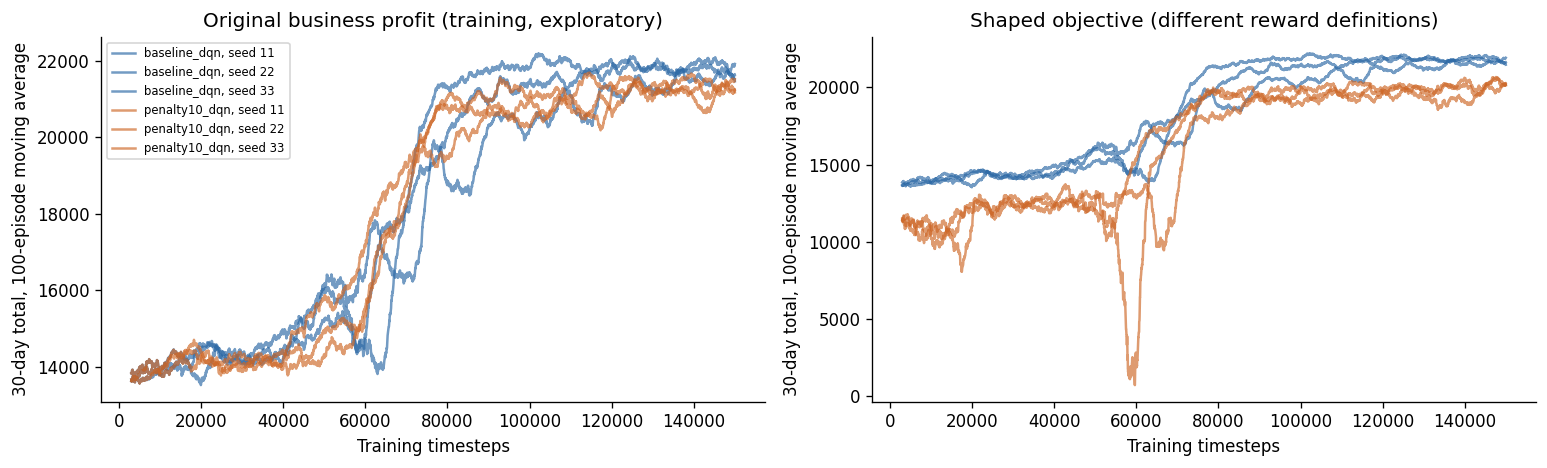

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


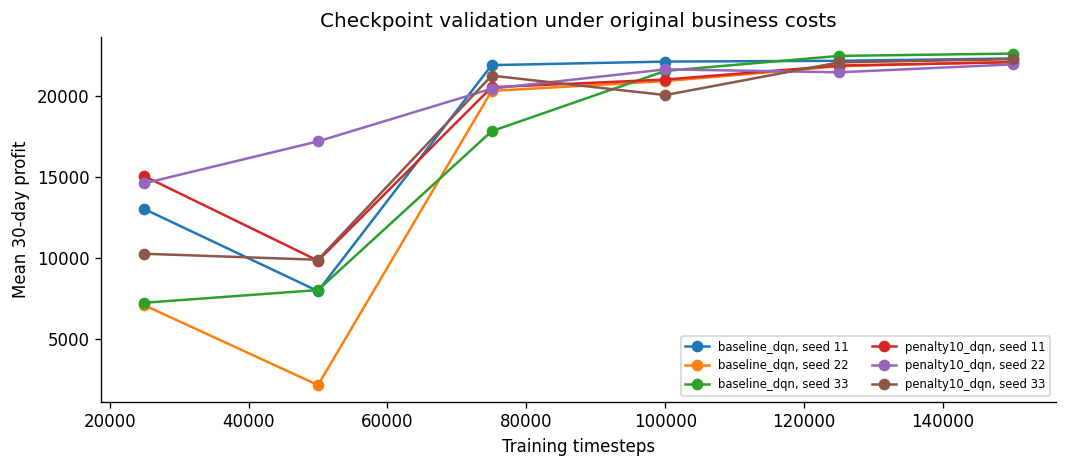

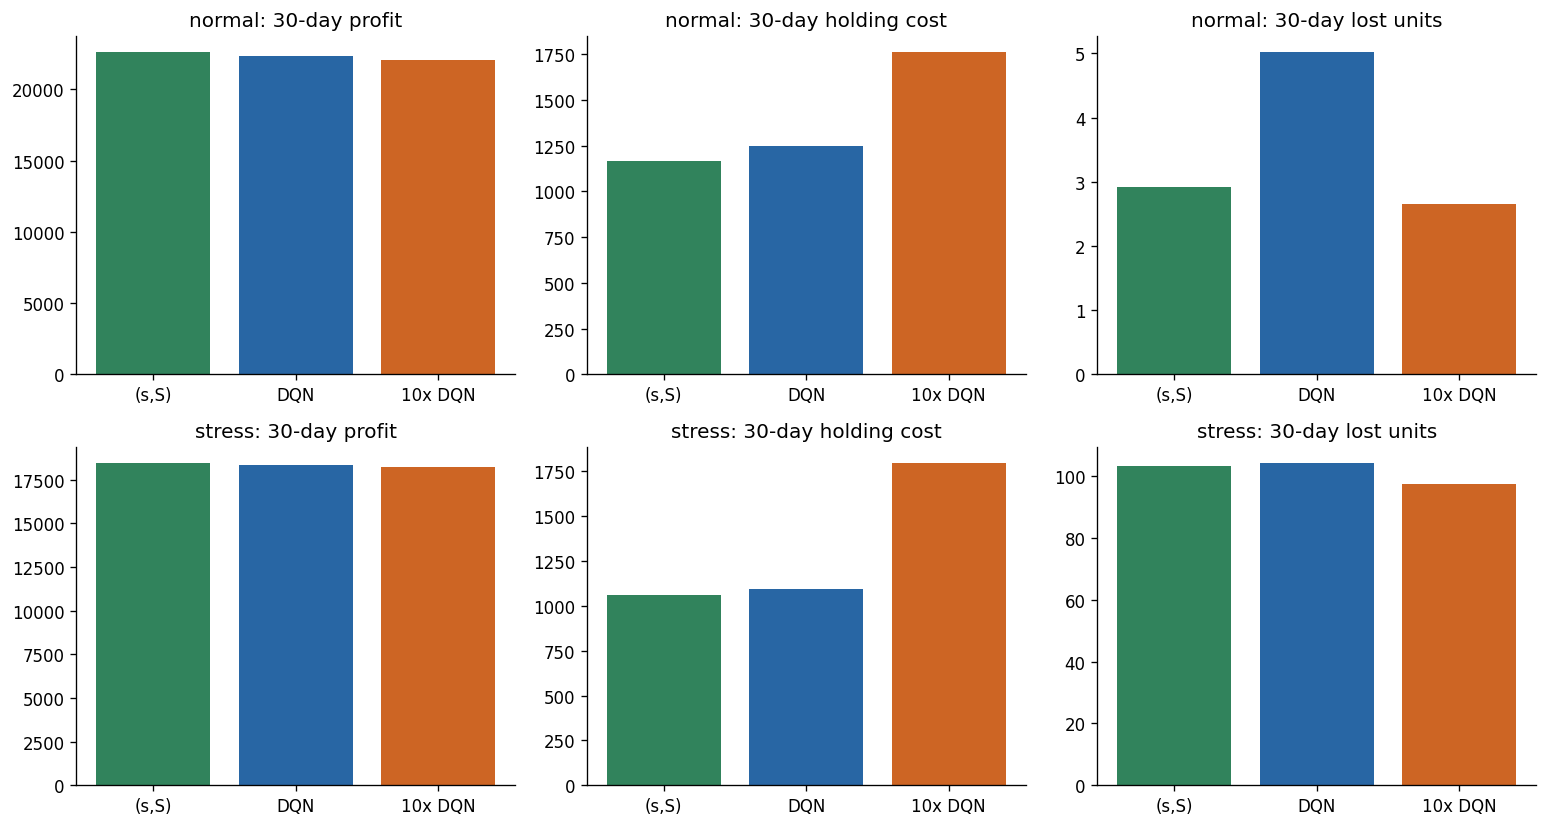

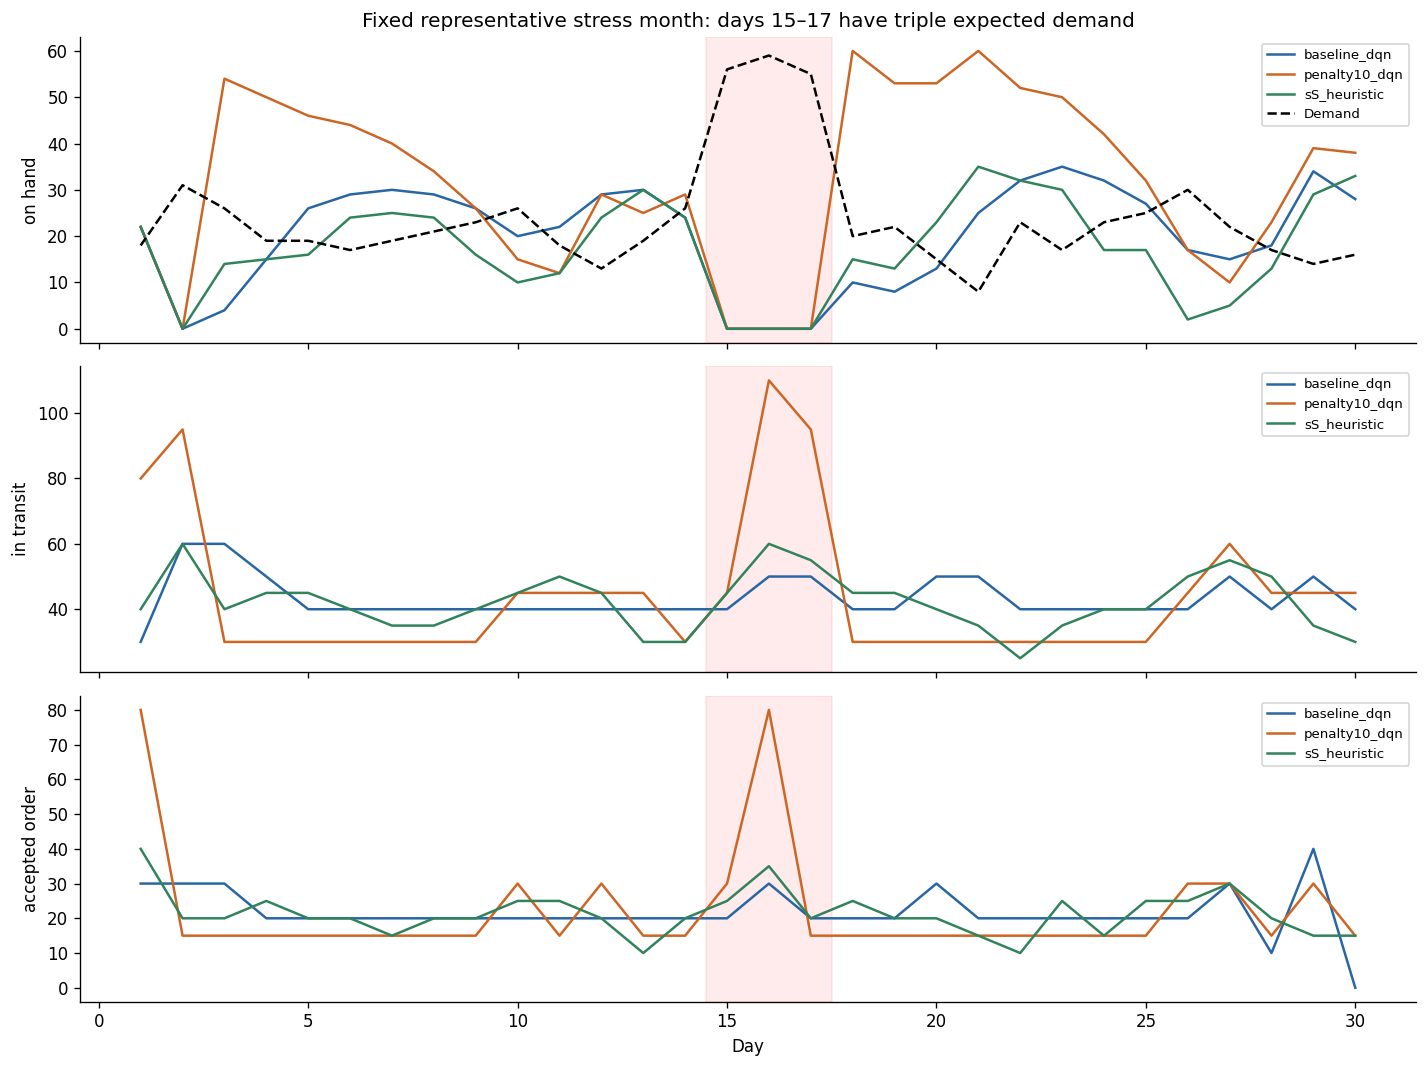

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [9]:
plot_results(metrics, trajectories, summary, training, validation, output=ARTIFACTS)


## 7. Evidence-based interpretation and failure diagnostics
The table below reports measured direction, including regressions. A stronger penalty is an *improvement candidate* and may trade profit/holding cost for fewer shortages; it is not assumed to win.

- The heuristic is a threshold/order-up-to rule; the DQN is a nonlinear action-value approximation over stock, pipeline and time. Mathematical flexibility does not imply superiority.
- Pipeline buckets expose when replenishment will arrive, enabling lead-time-aware action. A learned policy's competence must be checked in its trajectory and aggregate lost sales.
- IID demand is aleatoric uncertainty: identical states can have different next demands. Extra historical averages do not reveal an actual trend here.
- An unannounced shock cannot be predicted; reserve stock and replenishment determine resilience. Check recovery from the saved trajectory, and avoid generalizing a single episode.
- Low action diversity or many zero orders can indicate a poor policy. The diagnostics below and saved validation curves make that visible. Do not hide failed seeds or retune on final tests.

Remaining scope limits: custom rather than required environment; stylized prices/costs; conservative capacity reservation; ideal full-cost salvage; no multi-echelon suppliers, nonstationary training, real-data validation or deployment safeguards. Three seeds do not establish broad robustness.


In [10]:
for condition in ['normal','stress']:
    table=summary[summary.scenario==condition].set_index('policy')
    base=table.loc['baseline_dqn']; tuned=table.loc['penalty10_dqn']
    print(f"{condition}: 10x minus baseline monthly profit = {tuned.monthly_profit-base.monthly_profit:+.2f}; "
          f"lost units = {tuned.lost_units-base.lost_units:+.2f}; "
          f"holding = {tuned.monthly_holding-base.monthly_holding:+.2f}.")
diag=trajectories.groupby(['scenario','policy','training_seed']).agg(
    mean_accepted_order=('accepted_order','mean'),distinct_orders=('accepted_order','nunique'),
    zero_order_fraction=('accepted_order',lambda x: float((x==0).mean())),
    rejected_units=('rejected_order','sum'))
print('Fixed representative episode action diagnostics (not full-test averages):')
display(diag.round(3))
assert np.isfinite(metrics.business_profit).all()
assert metrics.groupby(['scenario','policy','training_seed']).size().eq(100).all()
print('All expected 100-episode policy/seed/condition groups are present.')


normal: 10x minus baseline monthly profit = -297.30; lost units = -2.37; holding = +510.90.
stress: 10x minus baseline monthly profit = -96.18; lost units = -6.71; holding = +699.78.
Fixed representative episode action diagnostics (not full-test averages):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


mean_accepted_order  distinct_orders  \
scenario policy        training_seed                                         
normal   baseline_dqn   11                         20.333                5   
                        22                         20.833                4   
                        33                         20.167                6   
         penalty10_dqn  11                         20.667                3   
                        22                         23.000                6   
                        33                         20.000                7   
         sS_heuristic  -1                          19.833                5   
stress   baseline_dqn   11                         21.667                5   
                        22                         22.000                5   
                        33                         21.000                7   
         penalty10_dqn  11                         22.333                3   
                        22                         22.667                6   
                        33                         22.000                6   
         sS_heuristic  -1                          21.333                7   

                                      zero_order_fraction  rejected_units  
scenario policy        training_seed                                       
normal   baseline_dqn   11                          0.033               0  
                        22                          0.000               0  
                        33                          0.000               0  
         penalty10_dqn  11                          0.000               0  
                        22                          0.000               0  
                        33                          0.000               0  
         sS_heuristic  -1                           0.000               0  
stress   baseline_dqn   11                          0.033               0  
                        22                          0.000               0  
                        33                          0.000               0  
         penalty10_dqn  11                          0.000               0  
                        22                          0.000               0  
                        33                          0.000               0  
         sS_heuristic  -1                           0.000               0

All expected 100-episode policy/seed/condition groups are present.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 8. Save and download the reproducibility package
The archive contains actual models, metrics, scenario banks, plots, test results, runtime manifest and runnable source. Download the **executed notebook separately** using Colab's File → Download → Download .ipynb so its cell outputs are preserved. This does not publish anything to GitHub.


In [11]:
Path('README.md').write_text("# Retail Inventory DQN: reproducible custom-simulator study\n\nRevision of the user-supplied `RL_Inventory_Management_FINAL (1).ipynb` and Project 5 brief. Original files remain unchanged. Authorship and reuse rights of the supplied reference have not been independently established; retain attribution and check permission before public publication.\n\n## Important assignment limitation\nThis is a **custom single-store, single-echelon Gymnasium simulator**, not `or-gym/InvManagement-v1`. That named environment is multi-echelon with a Box action space; this revision uses a discrete five-unit order grid. These are different models, and this notebook does not claim equivalence or instructor approval. If the assignment strictly requires `InvManagement-v1`, migration or an approved exception is still necessary.\n\n## Run in Colab\n1. Upload `Retail_Inventory_DQN_Reproducible_Study.ipynb` to Google Colab.\n2. Use a free CPU runtime. Run all cells from a fresh runtime. The notebook creates its own Python source, tests and requirements; no other uploaded files are needed.\n3. The pinned dependency cell must complete before imports. It installs CPU PyTorch from its official index and other packages from PyPI. No Drive mount, account secrets or remote publication is used.\n4. Read the environment test output and measured 10,000-step benchmark. Default experiment: 150,000 steps each for baseline and penalty-tuned DQN, each with seeds 11, 22, 33 (900,000 training steps total, plus a discarded benchmark).\n5. The final cell writes `retail_inventory_results.zip` with models, raw results, plots and this documentation. Download the executed notebook separately from Colab to retain its cell outputs.\n\n## Modeling choices\n- 30-day episodes; mean daily demand 20, IID Poisson; unannounced stress demand mean 60 on days 15–17.\n- Initial stock 40, two-day lead time, no opening pipeline, capacity 250, maximum daily order 120. Orders are selected in five-unit increments. Accepted quantity may be smaller when capacity binds.\n- Decisions use current on-hand, each pipeline bucket and time remaining, all scaled to [0,1]. Previous IID demand adds no true predictive signal and is omitted.\n- Order first, receive due stock, meet demand, charge holding. A day-t order arrives before demand on day t+2.\n- Capacity is conservatively reserved for on-hand plus **all in-transit inventory**. Orders above free reserved capacity are rejected explicitly. No arrivals vanish.\n- Original business economics: sale price 100, acquisition cost 60, end-of-day holding cost 2/unit/day, lost-sales penalty 50/unit. Opening inventory is purchased on day 1; terminal on-hand and pipeline inventory receive salvage credit at unit cost. Every policy gets identical treatment. This simplifying full-recovery salvage assumption is explicit; it is not a real-world cash-flow guarantee.\n- DQN uses gamma=1.0 for this finite, time-observed horizon so its objective aligns with undiscounted monthly profit. DQN reward is scaled by 1,000. The improved candidate multiplies the lost-sales penalty by 10 during training only. All reported final profit uses the **original** penalty of 50. Shaped rewards must not be compared as if they were the same economic objective.\n\n## Fairness and evaluation\n- Same architecture, action/observation space, optimizer, exploration schedule, training budgets and seed list for both RL variants.\n- `(s,S)` is tuned on 50 validation episodes. RL checkpoints are selected by original-cost mean validation profit every 25,000 steps.\n- Final test: 100 independent 30-day demand scenarios per condition. Every policy and seed sees the identical scenario bank within a condition. The normal and stress banks are distinct; there is no claim of a paired before/after causal shock estimate.\n- Test data is not used for tuning, selecting runs or changing hyperparameters. The fixed representative figure uses test episode 0 and training seed 11, rather than the most attractive trajectory.\n- Aggregate RL scores average seeds and episodes. Seeds share test demand, so 300 RL outcomes are not 300 independent demand scenarios. Per-seed metrics expose training variability. Paired bootstrap intervals average seeds within each episode and quantify demand-scenario uncertainty **conditional on these trained policies**, not full training-seed uncertainty.\n- A larger penalty is a tested improvement candidate, not a promised win. Report unfavorable or mixed outcomes honestly. Stress recovery and stockout avoidance must be established from measured metrics, not asserted.\n\n## Outputs\n- `artifacts/models/*_best.zip` and `*_final.zip`: actual trained SB3 models\n- `artifacts/metrics/`: training episodes, checkpoint validation, heuristic grid, test episode metrics, demand banks, seed summaries, paired profit differences and fixed representative trajectories\n- `artifacts/figures/`: training, validation, normal/stress comparison, stress trajectory\n- `artifacts/run_manifest.json`: actual runtime versions, device, seeds, timesteps and measured training durations\n- `artifacts/environment_tests.txt`: actual pytest result\n\n## Current verification status\nPrepared for Colab execution. Local training was stopped at the user's request before any trustworthy benchmark/training result was obtained. No saved original output is reused. Treat training, tests and outcome claims as unverified until the Colab cells complete and output artifacts are inspected. The runtime manifest and test log then record actual execution evidence.\n\n## Remaining limitations\nCustom environment differs from required or-gym; finite horizon and full-cost salvage simplify terminal economics; demand parameters and costs are stylized; no backorders, supplier uncertainty, nonstationary training, multi-product constraints or real data. Three training seeds are modest. A good simulator score is not evidence of safe retail deployment. This revision provides the experiment and a concise interpretation guide, not the later final written project report.\n")
Path('requirements.txt').write_text('# Install CPU torch separately using its official wheel index:\n# python -m pip install torch==2.7.1 --index-url https://download.pytorch.org/whl/cpu\ntorch==2.7.1\nstable-baselines3==2.7.0\ngymnasium==1.2.0\nnumpy==2.3.5\npandas==2.2.3\nmatplotlib==3.10.8\npytest==8.4.2\n')
import zipfile
# Replace preparation status only after this notebook reaches successful completion.
readme=Path('README.md').read_text()
old=readme.split('## Current verification status\n',1)[1].split('\n## Remaining limitations',1)[0]
readme=readme.replace(old,'Executed through the experiment and evaluation cells in this Colab runtime. See artifacts/environment_tests.txt and artifacts/run_manifest.json for actual test results, versions, seeds and timings. The executed notebook is downloaded separately.\n')
Path('README.md').write_text(readme)
manifest=json.loads((ARTIFACTS/'run_manifest.json').read_text())
manifest['notebook_completed']=True
manifest['benchmark']=benchmark
manifest['visible_cpu_count']=os.cpu_count()
(ARTIFACTS/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
archive=Path('retail_inventory_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for path in sorted(ARTIFACTS.rglob('*')):
        if path.is_file(): z.write(path,str(path))
    for name in ['inventory_experiment.py','test_inventory.py','README.md','requirements.txt']:
        z.write(name,name)
print(f'Saved {archive.resolve()} ({archive.stat().st_size/1e6:.1f} MB)')
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Outside Colab: collect the ZIP from the working directory.')


Saved /content/retail_inventory_results.zip (2.2 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>